# Group 5 – Time Series Analysis of Hanoi Garment CPI Data and Indonesia Economic Data
Part 1 uses `Data01_05_GarmentCPI.csv`, Part 2 uses `Data02_05_Indonesia_C.csv`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import IsolationForest
import ruptures as rpt

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["figure.dpi"] = 110

cpi = pd.read_csv("GrProjCPIData/Data01_05_GarmentCPI.csv")
cpi.columns = cpi.columns.str.strip()
cpi.index = pd.date_range("2015-01-01", periods=len(cpi), freq="MS")
s1 = cpi["GarmentFWHattoDecCPI"].rename("CPI (series 1)")
s3 = cpi["CPI_rate"].rename("CPI rate (series 3)")
SERIES = {"CPI (series 1)": s1, "CPI rate (series 3)": s3}
print(cpi.head())
print(cpi.shape)
print(cpi[["GarmentFWHattoDecCPI", "CPI_toPM", "CPI_rate"]].describe().round(3))

            Time  Year  Month  GarmentFWHattoDecCPI    CPI_toPM  CPI_rate
2015-01-01     1  2015      1                 100.7  100.700000  0.700000
2015-02-01     2  2015      2                 100.2   99.503476 -0.496524
2015-03-01     3  2015      3                 100.1   99.900200 -0.099800
2015-04-01     4  2015      4                 100.3  100.199800  0.199800
2015-05-01     5  2015      5                 100.3  100.000000  0.000000
(96, 6)
       GarmentFWHattoDecCPI  CPI_toPM  CPI_rate
count                96.000    96.000    96.000
mean                100.143   100.023     0.023
std                   0.196     0.214     0.214
min                  99.440    99.410    -0.590
25%                 100.060    99.900    -0.100
50%                 100.100   100.000     0.000
75%                 100.222   100.105     0.105
max                 100.700   100.700     0.700


## 1.1 Time series description – A. Time series plot

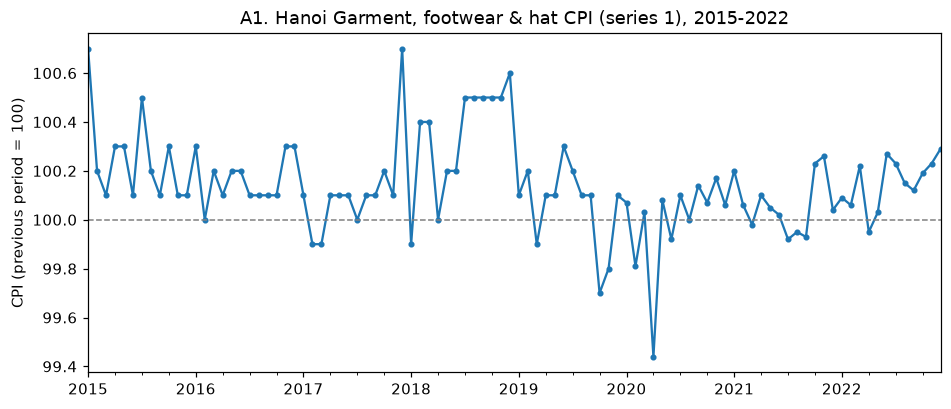

In [2]:
s1.plot(marker="o", ms=3, title="A1. Hanoi Garment, footwear & hat CPI (series 1), 2015-2022")
plt.axhline(100, color="grey", ls="--", lw=1)
plt.ylabel("CPI (previous period = 100)")
plt.show()

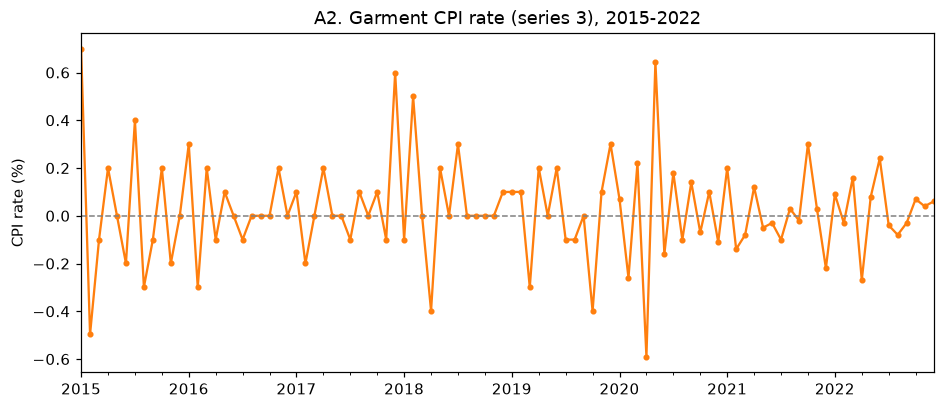

In [3]:
s3.plot(marker="o", ms=3, color="tab:orange", title="A2. Garment CPI rate (series 3), 2015-2022")
plt.axhline(0, color="grey", ls="--", lw=1)
plt.ylabel("CPI rate (%)")
plt.show()

## B. Time series trend checking
12-month rolling mean + linear regression of the series on time + seasonal profile by month.

In [4]:
def check_trend(s, color):
    t = np.arange(len(s))
    reg = stats.linregress(t, s.values)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(s.index, s, color=color, alpha=0.5, label="series")
    ax[0].plot(s.index, s.rolling(12).mean(), color="black", lw=2, label="12-month rolling mean")
    ax[0].plot(s.index, reg.intercept + reg.slope * t, "r--", label="linear trend")
    ax[0].legend(); ax[0].set_title(f"Trend of {s.name}")
    month_dev = s.groupby(s.index.month).mean() - s.mean()
    month_dev.plot(kind="bar", ax=ax[1], color=color)
    ax[1].set_title("Calendar-month mean minus overall mean"); ax[1].set_xlabel("month")
    plt.tight_layout(); plt.show()
    print(f"Linear trend: slope = {reg.slope:.5f} per month, p-value = {reg.pvalue:.4f}, R^2 = {reg.rvalue**2:.4f}")
    print("Month deviations:", month_dev.round(3).to_dict())
    print("Yearly means:"); print(s.groupby(s.index.year).mean().round(3).to_string())

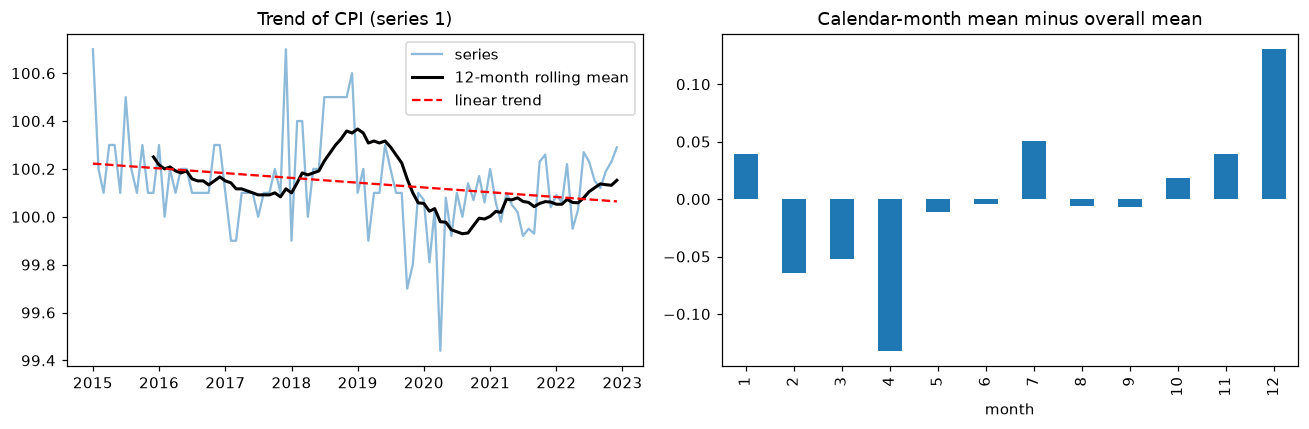

Linear trend: slope = -0.00166 per month, p-value = 0.0203, R^2 = 0.0560
Month deviations: {1: 0.039, 2: -0.065, 3: -0.052, 4: -0.132, 5: -0.011, 6: -0.005, 7: 0.05, 8: -0.006, 9: -0.007, 10: 0.018, 11: 0.039, 12: 0.13}
Yearly means:
2015    100.250
2016    100.167
2017    100.117
2018    100.350
2019    100.058
2020     99.991
2021    100.062
2022    100.152


In [5]:
check_trend(s1, "tab:blue")

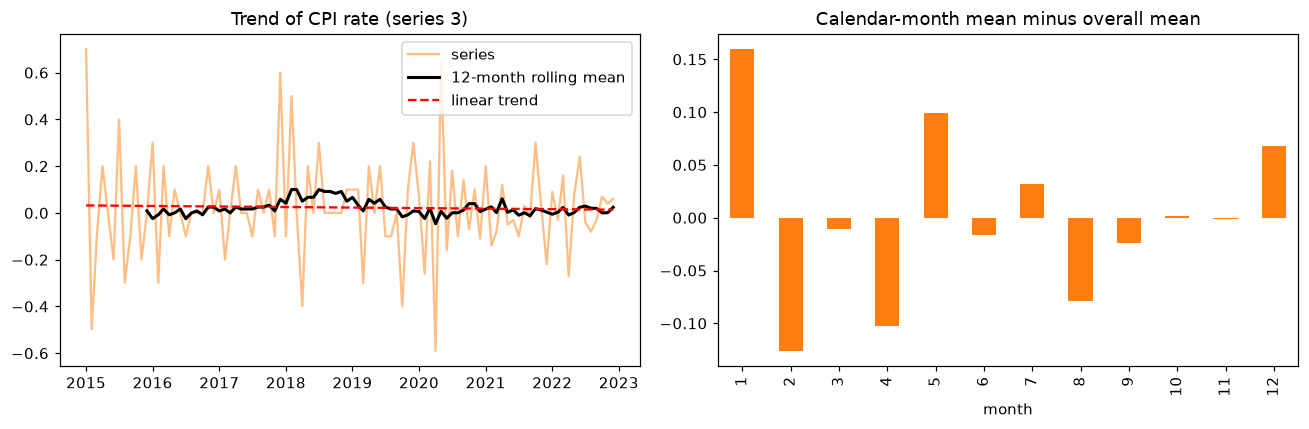

Linear trend: slope = -0.00019 per month, p-value = 0.8107, R^2 = 0.0006
Month deviations: {1: 0.16, 2: -0.126, 3: -0.01, 4: -0.103, 5: 0.099, 6: -0.017, 7: 0.032, 8: -0.079, 9: -0.024, 10: 0.002, 11: -0.002, 12: 0.068}
Yearly means:
2015    0.009
2016    0.025
2017    0.058
2018    0.050
2019    0.009
2020    0.005
2021    0.003
2022    0.024


In [6]:
check_trend(s3, "tab:orange")

## C. Autocorrelation function (ACF)

In [7]:
def significant_lags(values, confint):
    # a lag is significant when the 95% confidence band (centred on 0) does not contain the coefficient
    half = confint[:, 1] - values
    return [k for k in range(1, len(values)) if abs(values[k]) > half[k]]

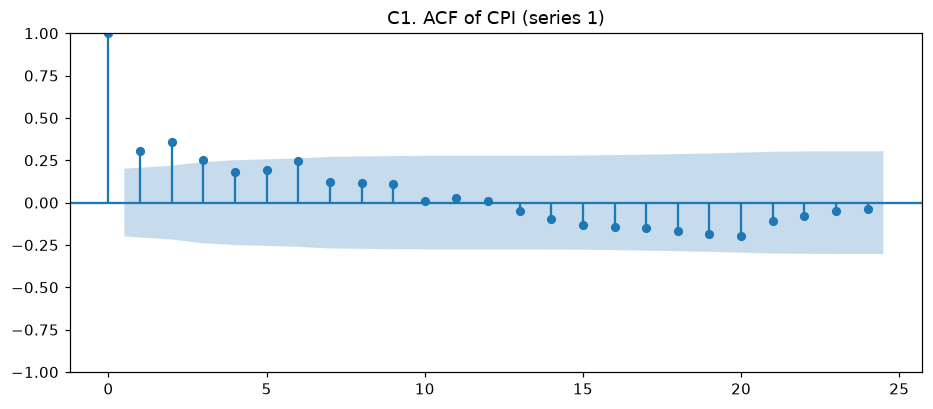

ACF lags 1-12: [0.306 0.355 0.253 0.18  0.193 0.247 0.123 0.115 0.108 0.009 0.029 0.01 ]
Significant ACF lags: [1, 2, 3]


In [8]:
plot_acf(s1, lags=24, title="C1. ACF of CPI (series 1)"); plt.show()
a1, ci = acf(s1, nlags=24, alpha=0.05)
print("ACF lags 1-12:", np.round(a1[1:13], 3))
print("Significant ACF lags:", significant_lags(a1, ci))

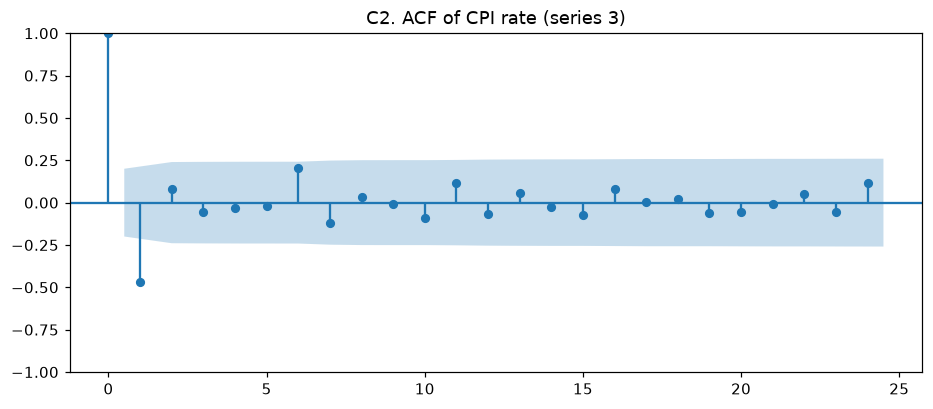

ACF lags 1-12: [-0.466  0.081 -0.053 -0.034 -0.023  0.204 -0.119  0.034 -0.01  -0.089
  0.116 -0.067]
Significant ACF lags: [1]


In [9]:
plot_acf(s3, lags=24, title="C2. ACF of CPI rate (series 3)"); plt.show()
a3, ci = acf(s3, nlags=24, alpha=0.05)
print("ACF lags 1-12:", np.round(a3[1:13], 3))
print("Significant ACF lags:", significant_lags(a3, ci))

## D. Partial autocorrelation function (PACF)

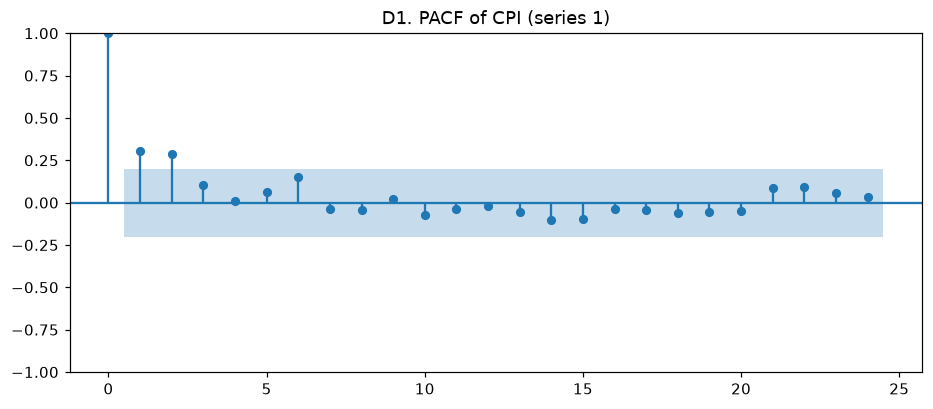

PACF lags 1-12: [ 0.306  0.289  0.105  0.007  0.065  0.153 -0.04  -0.043  0.022 -0.074
 -0.035 -0.02 ]
Significant PACF lags: [1, 2]


In [10]:
plot_pacf(s1, lags=24, method="ywm", title="D1. PACF of CPI (series 1)"); plt.show()
pa1, ci = pacf(s1, nlags=24, method="ywm", alpha=0.05)
print("PACF lags 1-12:", np.round(pa1[1:13], 3))
print("Significant PACF lags:", significant_lags(pa1, ci))

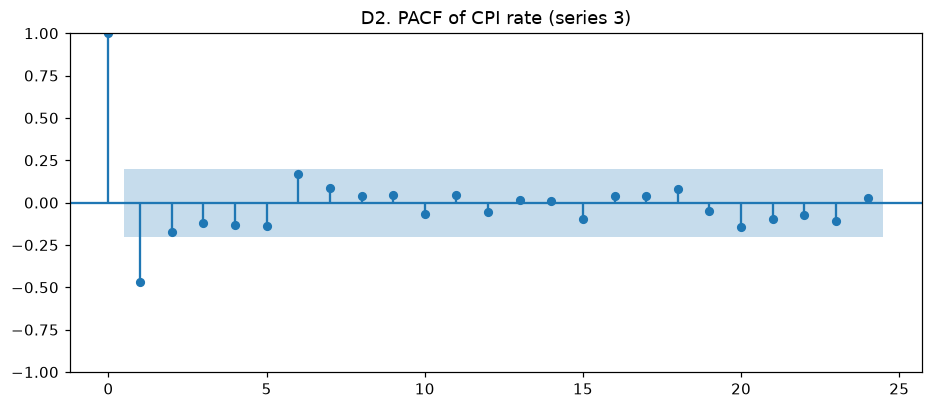

PACF lags 1-12: [-0.466 -0.174 -0.118 -0.133 -0.14   0.167  0.084  0.039  0.047 -0.07
  0.044 -0.055]
Significant PACF lags: [1]


In [11]:
plot_pacf(s3, lags=24, method="ywm", title="D2. PACF of CPI rate (series 3)"); plt.show()
pa3, ci = pacf(s3, nlags=24, method="ywm", alpha=0.05)
print("PACF lags 1-12:", np.round(pa3[1:13], 3))
print("Significant PACF lags:", significant_lags(pa3, ci))

## E. Stationarity test (ADF: H0 = unit root; KPSS: H0 = stationary)

In [12]:
def stationarity_test(s):
    adf = adfuller(s, autolag="AIC")
    print(f"ADF  statistic = {adf[0]:.4f}, p-value = {adf[1]:.6f}, lags used = {adf[2]}")
    print("     critical values:", {k: round(float(v), 3) for k, v in adf[4].items()})
    print("     ->", "stationary (reject H0)" if adf[1] < 0.05 else "non-stationary (cannot reject H0)")
    with warnings.catch_warnings():   # KPSS warns when p-value is beyond its table (p > 0.1)
        warnings.simplefilter("ignore")
        k = kpss(s, regression="c", nlags="auto")
    print(f"KPSS statistic = {k[0]:.4f}, p-value = {k[1]:.4f}")
    print("     ->", "stationary (cannot reject H0)" if k[1] >= 0.05 else "non-stationary (reject H0)")

In [13]:
stationarity_test(s1)

ADF  statistic = -4.2149, p-value = 0.000622, lags used = 1
     critical values: {'1%': -3.502, '5%': -2.893, '10%': -2.583}
     -> stationary (reject H0)
KPSS statistic = 0.3602, p-value = 0.0943
     -> stationary (cannot reject H0)


In [14]:
stationarity_test(s3)

ADF  statistic = -6.6319, p-value = 0.000000, lags used = 3
     critical values: {'1%': -3.504, '5%': -2.894, '10%': -2.584}
     -> stationary (reject H0)
KPSS statistic = 0.1049, p-value = 0.1000
     -> stationary (cannot reject H0)


## 1.4 Estimating ARIMA models and model selection
Grid over p = 0..p_max, q = 0..q_max with d = 0 (from step 1.3). A model is *stable* when the 95%
confidence interval of every ARMA coefficient (ar.L*, ma.L*) excludes 0.

In [15]:
def quiet_fit(data, order, seasonal_order=(0, 0, 0, 0)):
    # statsmodels re-enables its own warnings inside fit(), so silence them here
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ARIMA(data, order=order, seasonal_order=seasonal_order).fit()

def arima_grid(s, p_max, d, q_max):
    rows = []
    for p in range(p_max + 1):
        for q in range(q_max + 1):
            res = quiet_fit(s, (p, d, q))
            ci = res.conf_int()
            arma = [n for n in res.params.index if n.startswith(("ar.", "ma."))]
            stable = all(not (ci.loc[n, 0] <= 0 <= ci.loc[n, 1]) for n in arma)
            rows.append({"order": (p, d, q), "AIC": round(res.aic, 3), "BIC": round(res.bic, 3), "stable": stable})
    table = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
    best = table[table.stable].iloc[0]["order"]
    return table, best

In [16]:
P1, D1, Q1 = 2, 0, 3   # maxima from step 1.3
table1, best1 = arima_grid(s1, P1, D1, Q1)
print(table1.to_string())

        order     AIC     BIC  stable
0   (1, 0, 1) -52.988 -42.730    True
1   (2, 0, 0) -52.839 -42.581    True
2   (2, 0, 1) -51.933 -39.112   False
3   (1, 0, 2) -51.681 -38.859   False
4   (1, 0, 3) -50.525 -35.139   False
5   (2, 0, 2) -50.039 -34.653   False
6   (0, 0, 3) -49.778 -36.957   False
7   (0, 0, 2) -48.961 -38.704   False
8   (2, 0, 3) -48.529 -30.579   False
9   (1, 0, 0) -45.908 -38.215    True
10  (0, 0, 1) -41.859 -34.166    True
11  (0, 0, 0) -37.576 -32.447    True


In [17]:
print("Best stable model for CPI (series 1): ARIMA", best1)
best_fit1 = quiet_fit(s1, best1)
print(best_fit1.summary().tables[1])
print(f"AIC = {best_fit1.aic:.3f}")

Best stable model for CPI (series 1): ARIMA (1, 0, 1)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        100.1593      0.045   2222.718      0.000     100.071     100.248
ar.L1          0.8742      0.088      9.912      0.000       0.701       1.047
ma.L1         -0.6316      0.143     -4.426      0.000      -0.911      -0.352
sigma2         0.0309      0.003      9.133      0.000       0.024       0.038
AIC = -52.988


In [18]:
P3, D3, Q3 = 1, 0, 1   # maxima from step 1.3
table3, best3 = arima_grid(s3, P3, D3, Q3)
print(table3.to_string())

       order     AIC     BIC  stable
0  (0, 0, 1) -48.960 -41.267    True
1  (1, 0, 1) -47.754 -37.497   False
2  (1, 0, 0) -45.260 -37.567    True
3  (0, 0, 0) -20.767 -15.639    True


In [19]:
print("Best stable model for CPI rate (series 3): ARIMA", best3)
best_fit3 = quiet_fit(s3, best3)
print(best_fit3.summary().tables[1])
print(f"AIC = {best_fit3.aic:.3f}")

Best stable model for CPI rate (series 3): ARIMA (0, 0, 1)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0205      0.009      2.365      0.018       0.004       0.037
ma.L1         -0.5688      0.062     -9.230      0.000      -0.690      -0.448
sigma2         0.0329      0.003      9.858      0.000       0.026       0.039
AIC = -48.960


## 1.5 Mean values forecasting (next 12 months, 2023)

In [20]:
def forecast_mean(fit, s, steps=12, color="tab:blue"):
    fc = fit.get_forecast(steps=steps)
    mean, ci = fc.predicted_mean, fc.conf_int(alpha=0.05)
    out = pd.DataFrame({"forecast": mean, "lower 95%": ci.iloc[:, 0], "upper 95%": ci.iloc[:, 1]}).round(3)
    out.index = out.index.strftime("%Y-%m")
    print(out.to_string())
    ax = s.plot(color=color, label="observed")
    fit.fittedvalues.plot(ax=ax, color="green", alpha=0.6, label="fitted")
    mean.plot(ax=ax, color="red", label="forecast")
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="red", alpha=0.15, label="95% CI")
    ax.legend(); ax.set_title(f"12-month mean forecast of {s.name}"); plt.show()

         forecast  lower 95%  upper 95%
2023-01   100.203     99.858    100.547
2023-02   100.197     99.843    100.552
2023-03   100.192     99.830    100.554
2023-04   100.188     99.821    100.556
2023-05   100.185     99.813    100.556
2023-06   100.181     99.806    100.556
2023-07   100.179     99.801    100.556
2023-08   100.176     99.797    100.555
2023-09   100.174     99.793    100.555
2023-10   100.172     99.791    100.554
2023-11   100.171     99.788    100.553
2023-12   100.169     99.786    100.552


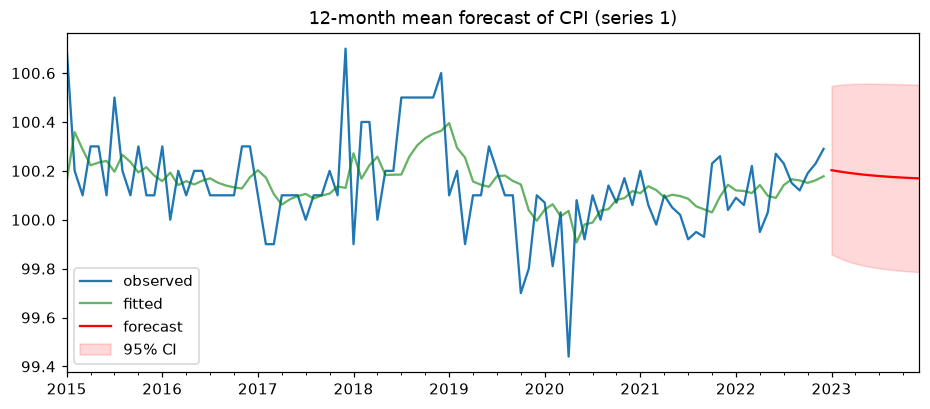

In [21]:
forecast_mean(best_fit1, s1)

         forecast  lower 95%  upper 95%
2023-01    -0.007     -0.363      0.348
2023-02     0.020     -0.388      0.429
2023-03     0.020     -0.388      0.429
2023-04     0.020     -0.388      0.429
2023-05     0.020     -0.388      0.429
2023-06     0.020     -0.388      0.429
2023-07     0.020     -0.388      0.429
2023-08     0.020     -0.388      0.429
2023-09     0.020     -0.388      0.429
2023-10     0.020     -0.388      0.429
2023-11     0.020     -0.388      0.429
2023-12     0.020     -0.388      0.429


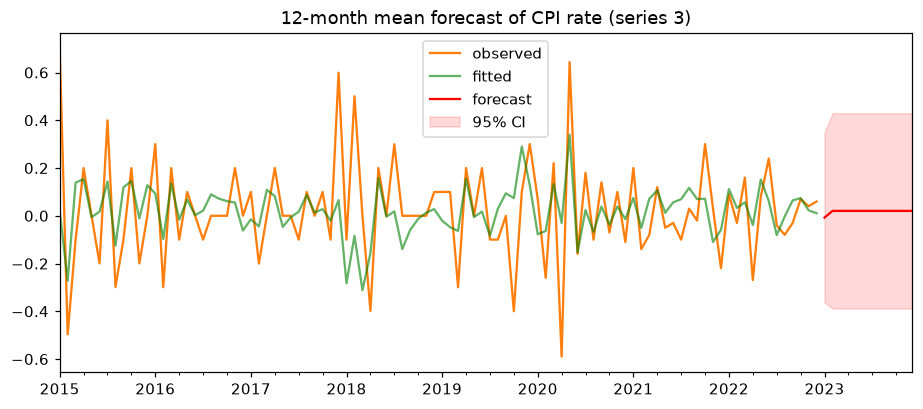

In [22]:
forecast_mean(best_fit3, s3, color="tab:orange")

## 1.6 Machine learning in ARIMA forecasting
80% train / 20% test, walk-forward validation: re-fit on all history, forecast one month ahead, then
add the true value to the history.

In [23]:
def split(s, ratio=0.8):
    n = int(len(s) * ratio)
    return s.iloc[:n], s.iloc[n:]

def walk_forward(s, order, seasonal_order=(0, 0, 0, 0)):
    train, test = split(s)
    history, preds = list(train), []
    for actual in test:
        fit = quiet_fit(history, order, seasonal_order)
        preds.append(fit.forecast()[0])
        history.append(actual)
    preds = pd.Series(preds, index=test.index)
    rmse = np.sqrt(mean_squared_error(test, preds))
    return preds, rmse

def plot_test(s, preds, title):
    train, test = split(s)
    ax = train.plot(label="train", color="grey")
    test.plot(ax=ax, label="test (actual)", color="tab:blue", marker="o", ms=3)
    preds.plot(ax=ax, label="prediction", color="red", marker="x", ms=4)
    ax.legend(); ax.set_title(title); plt.show()

In [24]:
train1, test1 = split(s1)
print(f"Train: {train1.index[0]:%Y-%m} .. {train1.index[-1]:%Y-%m}  ({len(train1)} obs)")
print(f"Test : {test1.index[0]:%Y-%m} .. {test1.index[-1]:%Y-%m}  ({len(test1)} obs)")

Train: 2015-01 .. 2021-04  (76 obs)
Test : 2021-05 .. 2022-12  (20 obs)


ARIMA(1, 0, 1): test RMSE = 0.1146


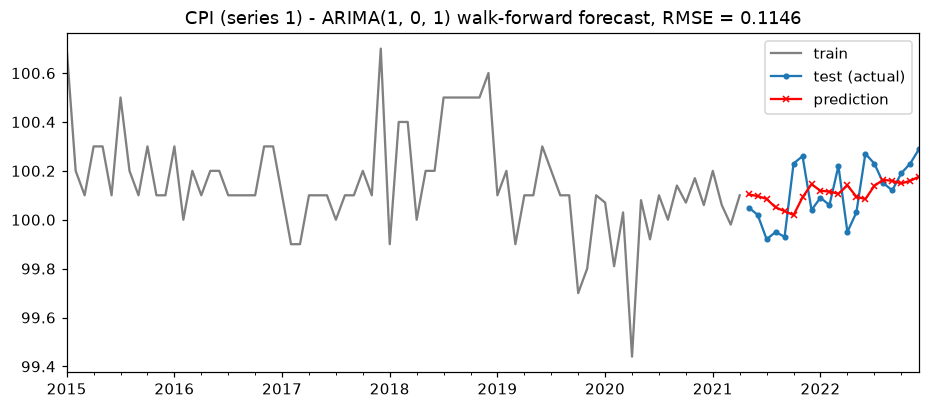

    order   RMSE
(1, 0, 1) 0.1146
(1, 0, 0) 0.1149
(0, 0, 1) 0.1179
(2, 0, 2) 0.1211
(2, 0, 1) 0.1213
(2, 0, 0) 0.1226
(1, 0, 2) 0.1230
(1, 0, 3) 0.1251
(2, 0, 3) 0.1257
(0, 0, 0) 0.1263
(0, 0, 2) 0.1325
(0, 0, 3) 0.1348


In [25]:
preds1, rmse1 = walk_forward(s1, best1)
print(f"ARIMA{best1}: test RMSE = {rmse1:.4f}")
plot_test(s1, preds1, f"CPI (series 1) - ARIMA{best1} walk-forward forecast, RMSE = {rmse1:.4f}")
rmse_grid1 = pd.DataFrame([{"order": str(o), "RMSE": round(walk_forward(s1, o)[1], 4)} for o in table1.order])
print(rmse_grid1.sort_values("RMSE").to_string(index=False))

In [26]:
train3, test3 = split(s3)
print(f"Train: {train3.index[0]:%Y-%m} .. {train3.index[-1]:%Y-%m}  ({len(train3)} obs)")
print(f"Test : {test3.index[0]:%Y-%m} .. {test3.index[-1]:%Y-%m}  ({len(test3)} obs)")

Train: 2015-01 .. 2021-04  (76 obs)
Test : 2021-05 .. 2022-12  (20 obs)


ARIMA(0, 0, 1): test RMSE = 0.1195


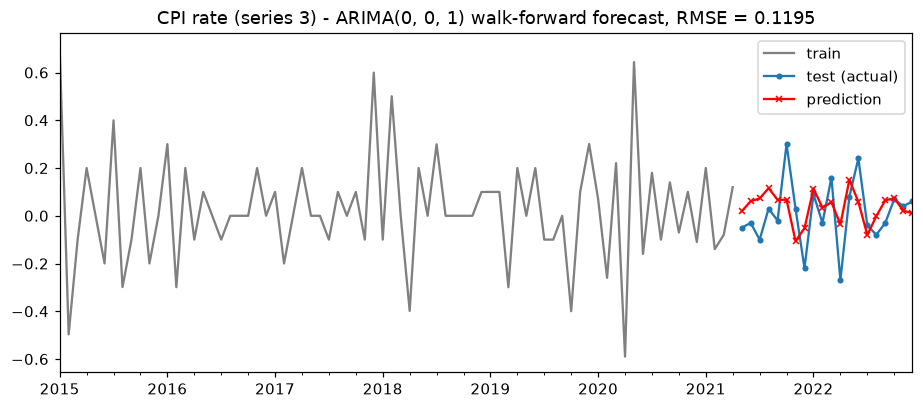

    order   RMSE
(0, 0, 1) 0.1195
(1, 0, 1) 0.1239
(0, 0, 0) 0.1320
(1, 0, 0) 0.1337


In [27]:
preds3, rmse3 = walk_forward(s3, best3)
print(f"ARIMA{best3}: test RMSE = {rmse3:.4f}")
plot_test(s3, preds3, f"CPI rate (series 3) - ARIMA{best3} walk-forward forecast, RMSE = {rmse3:.4f}")
rmse_grid3 = pd.DataFrame([{"order": str(o), "RMSE": round(walk_forward(s3, o)[1], 4)} for o in table3.order])
print(rmse_grid3.sort_values("RMSE").to_string(index=False))

## 1.7 Machine learning in SARIMA forecasting – SARIMA(pO,dO,qO)(P,0,Q,12)

In [28]:
def sarima_grid(s, order, PQ=range(3)):
    rows = []
    for P in PQ:
        for Q in PQ:
            rows.append({"seasonal (P,D,Q,m)": (P, 0, Q, 12), "RMSE": round(walk_forward(s, order, (P, 0, Q, 12))[1], 4)})
    table = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
    # (0,0,0,12) is plain ARIMA: keep it as the baseline but pick the best truly seasonal model
    best = table[table["seasonal (P,D,Q,m)"] != (0, 0, 0, 12)].iloc[0]["seasonal (P,D,Q,m)"]
    return table, best

SARIMA(1, 0, 1)(1,0,1,12): test RMSE = 0.1168


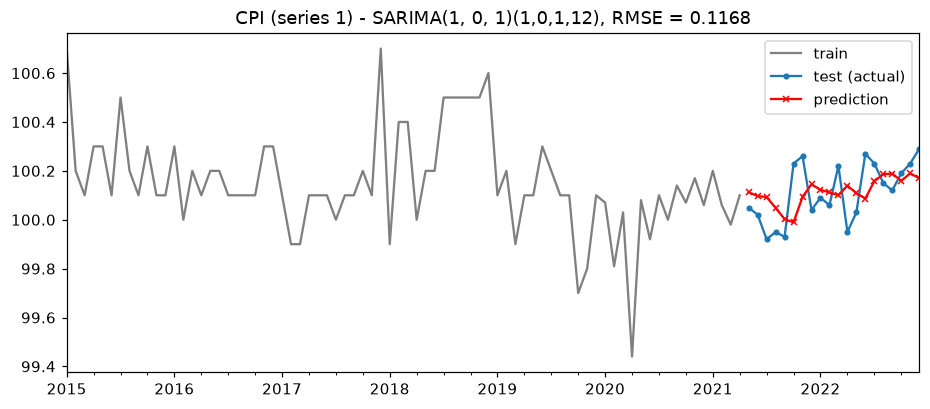

In [29]:
sp1, srmse1 = walk_forward(s1, best1, (1, 0, 1, 12))
print(f"SARIMA{best1}(1,0,1,12): test RMSE = {srmse1:.4f}")
plot_test(s1, sp1, f"CPI (series 1) - SARIMA{best1}(1,0,1,12), RMSE = {srmse1:.4f}")

  seasonal (P,D,Q,m)    RMSE
0      (0, 0, 0, 12)  0.1146
1      (0, 0, 1, 12)  0.1153
2      (1, 0, 0, 12)  0.1154
3      (1, 0, 1, 12)  0.1168
4      (2, 0, 1, 12)  0.1196
5      (2, 0, 0, 12)  0.1202
6      (0, 0, 2, 12)  0.1216
7      (1, 0, 2, 12)  0.1249
8      (2, 0, 2, 12)  0.1261


Best: SARIMA(1, 0, 1)(0, 0, 1, 12), RMSE = 0.1153  (plain ARIMA(1, 0, 1): 0.1146)


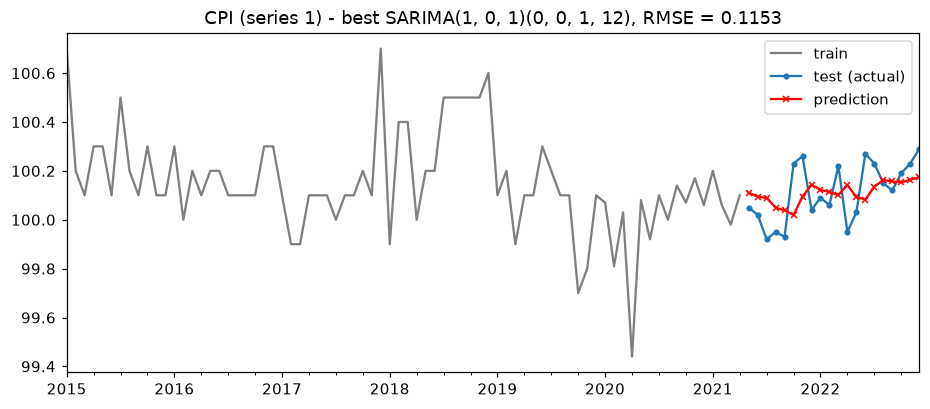

In [30]:
sg1, bs1 = sarima_grid(s1, best1)
print(sg1.to_string())
bp1, brmse1 = walk_forward(s1, best1, bs1)
print(f"Best: SARIMA{best1}{bs1}, RMSE = {brmse1:.4f}  (plain ARIMA{best1}: {rmse1:.4f})")
plot_test(s1, bp1, f"CPI (series 1) - best SARIMA{best1}{bs1}, RMSE = {brmse1:.4f}")

SARIMA(0, 0, 1)(1,0,1,12): test RMSE = 0.1220


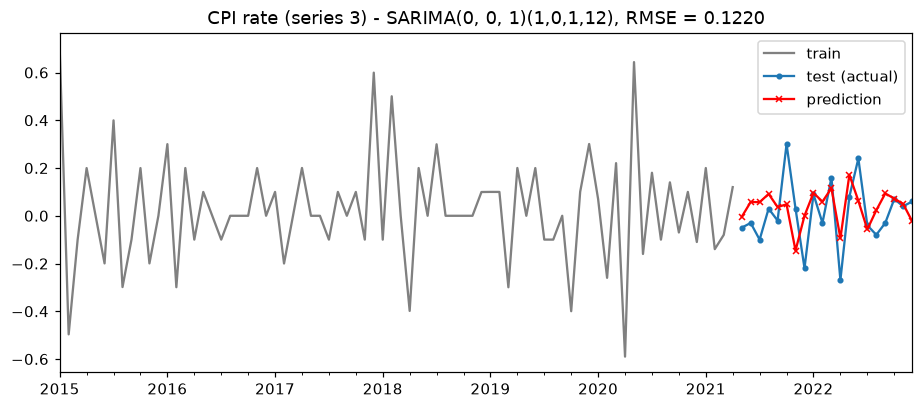

In [31]:
sp3, srmse3 = walk_forward(s3, best3, (1, 0, 1, 12))
print(f"SARIMA{best3}(1,0,1,12): test RMSE = {srmse3:.4f}")
plot_test(s3, sp3, f"CPI rate (series 3) - SARIMA{best3}(1,0,1,12), RMSE = {srmse3:.4f}")

  seasonal (P,D,Q,m)    RMSE
0      (0, 0, 0, 12)  0.1195
1      (0, 0, 1, 12)  0.1196
2      (1, 0, 0, 12)  0.1196
3      (1, 0, 1, 12)  0.1220
4      (2, 0, 0, 12)  0.1258
5      (0, 0, 2, 12)  0.1261
6      (2, 0, 1, 12)  0.1282
7      (2, 0, 2, 12)  0.1287
8      (1, 0, 2, 12)  0.1309


Best: SARIMA(0, 0, 1)(0, 0, 1, 12), RMSE = 0.1196  (plain ARIMA(0, 0, 1): 0.1195)


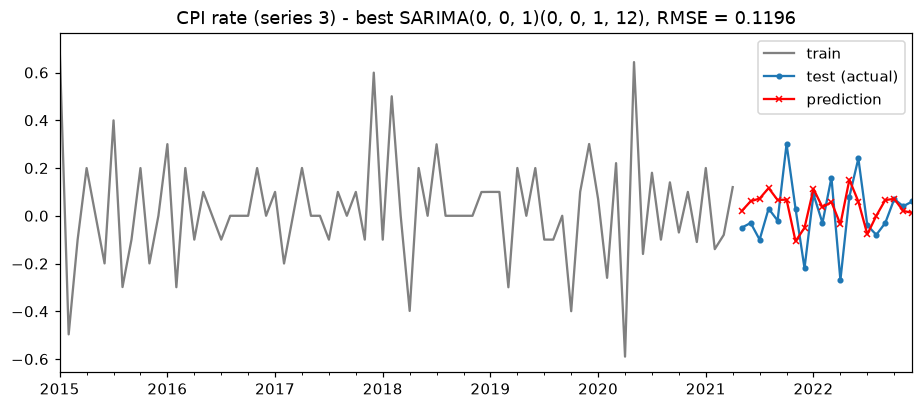

In [32]:
sg3, bs3 = sarima_grid(s3, best3)
print(sg3.to_string())
bp3, brmse3 = walk_forward(s3, best3, bs3)
print(f"Best: SARIMA{best3}{bs3}, RMSE = {brmse3:.4f}  (plain ARIMA{best3}: {rmse3:.4f})")
plot_test(s3, bp3, f"CPI rate (series 3) - best SARIMA{best3}{bs3}, RMSE = {brmse3:.4f}")

# Part 2 – Anomalies and change points in Indonesia economic data (1990-2021)

In [33]:
eco = pd.read_csv("GrProjEconData/Data02_05_Indonesia_C.csv", index_col="year")
print(eco.drop(columns="country").describe().T.round(3))
print("Missing values:", eco.isna().sum()[eco.isna().sum() > 0].to_dict())
COLS = ["ggdp", "mil", "inf", "fdi", "gdp"]
NAMES = {"ggdp": "Green GDP (USD)", "mil": "Military spending (% of GDP)", "inf": "Inflation (%)",
         "fdi": "FDI net inflows (USD)", "gdp": "GDP (USD)"}

def get(col):
    return eco[col].dropna()   # missing years are skipped, not imputed

      count          mean           std           min           25%  \
ggdp   30.0  4.467000e+11  3.461709e+11  8.600000e+10  1.550000e+11   
mil    31.0  1.192000e+00  6.790000e-01  5.710000e-01  7.060000e-01   
inf    32.0  8.781000e+00  9.832000e+00  1.560000e+00  4.360000e+00   
fdi    32.0  8.887605e+09  9.445324e+09 -4.550355e+09  1.703250e+09   
gdp    32.0  5.095351e+11  3.804358e+11  9.544555e+10  1.739242e+11   

               50%           75%           max  
ggdp  2.500000e+11  8.475000e+11  1.100000e+12  
mil   9.190000e-01  1.340000e+00  2.883000e+00  
inf   6.410000e+00  9.483000e+00  5.845100e+01  
fdi   4.895785e+09  1.932609e+10  2.512073e+10  
gdp   3.255000e+11  8.980000e+11  1.190000e+12  
Missing values: {'ggdp': 2, 'mil': 1}


## 2.1 Z-score method (|z| > 3)

In [34]:
def zscore_anomalies(col, threshold=3):
    s = get(col)
    z = (s - s.mean()) / s.std()
    out = s[z.abs() > threshold]
    ax = s.plot(marker="o", ms=4, title=f"Z-score anomalies (|z| > {threshold}) - {NAMES[col]}")
    ax.scatter(out.index, out, color="red", s=80, zorder=3, label="anomaly")
    ax.legend(); plt.show()
    print(pd.DataFrame({"value": s, "z": z.round(3)}).loc[z.abs().sort_values(ascending=False).index[:3]])
    print("Anomalies:", {int(y): round(float(v), 3) for y, v in out.items()} or "none")

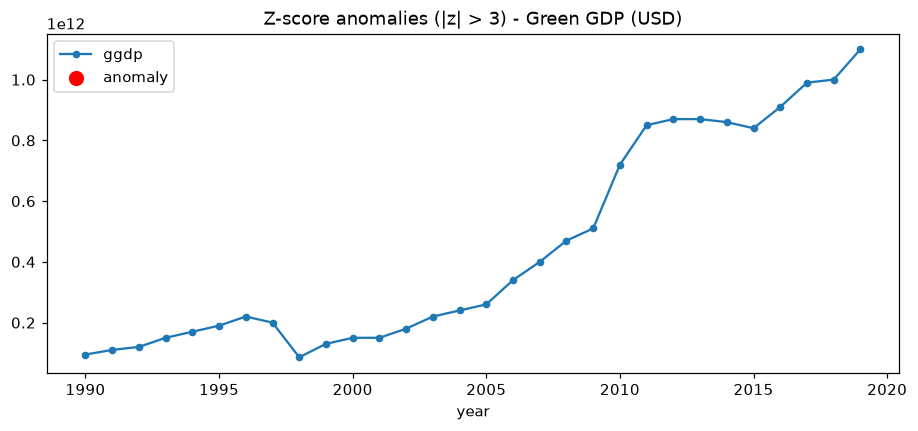

             value      z
year                     
2019  1.100000e+12  1.887
2018  1.000000e+12  1.598
2017  9.900000e+11  1.569
Anomalies: none


In [35]:
zscore_anomalies("ggdp")

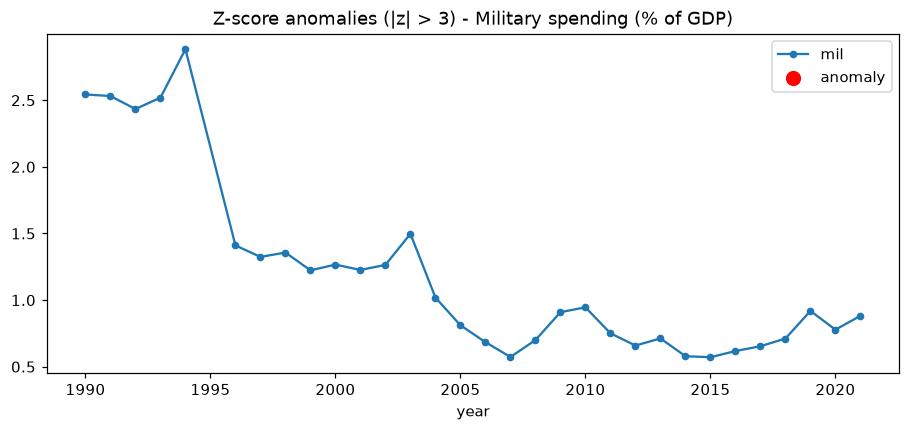

         value      z
year                 
1994  2.882670  2.489
1990  2.543151  1.989
1991  2.531463  1.972
Anomalies: none


In [36]:
zscore_anomalies("mil")

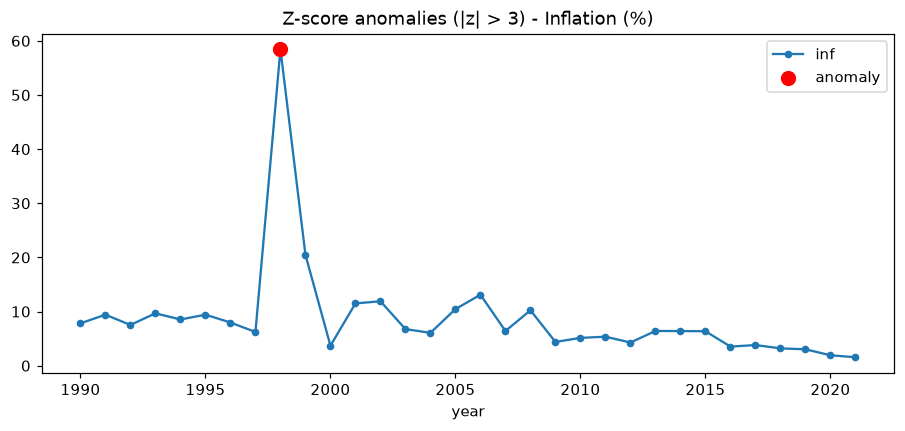

          value      z
year                  
1998  58.451044  5.052
1999  20.477831  1.190
2021   1.560130 -0.734
Anomalies: {1998: 58.451}


In [37]:
zscore_anomalies("inf")

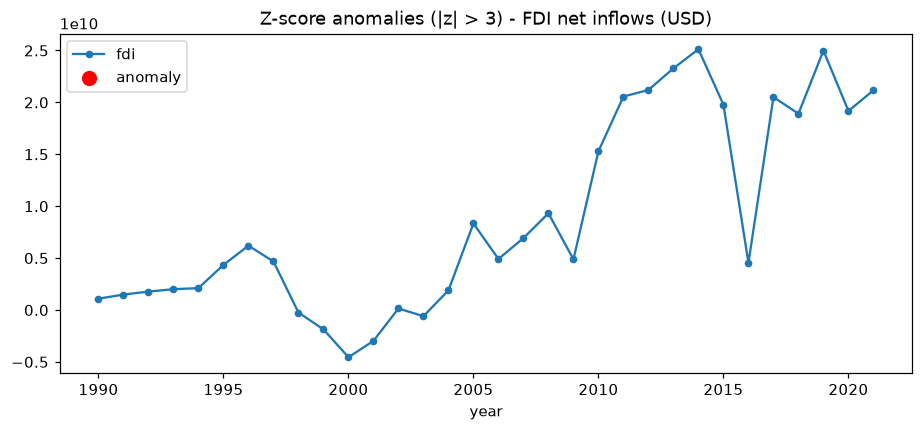

             value      z
year                     
2014  2.512073e+10  1.719
2019  2.499355e+10  1.705
2013  2.328174e+10  1.524
Anomalies: none


In [38]:
zscore_anomalies("fdi")

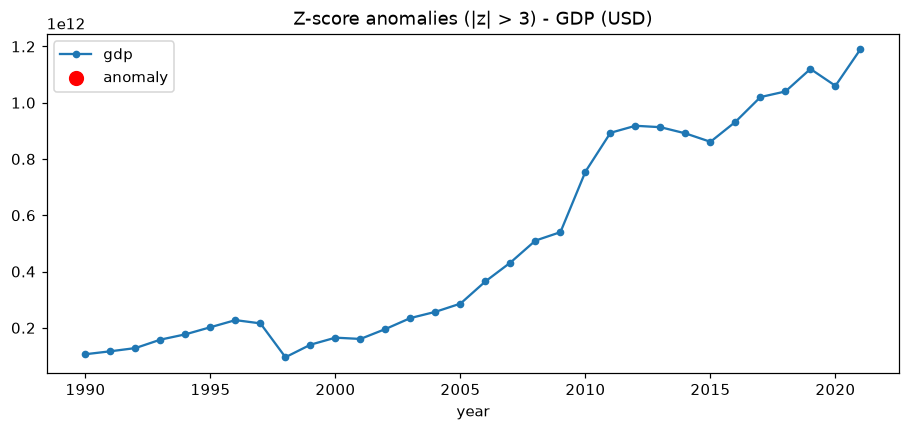

              value      z
year                      
2021  1190000000000  1.789
2019  1120000000000  1.605
2020  1060000000000  1.447
Anomalies: none


In [39]:
zscore_anomalies("gdp")

## 2.1 Isolation Forest (contamination = 0.1, i.e. about 3 of 32 years)

In [40]:
def iforest_anomalies(col, contamination=0.1):
    s = get(col)
    model = IsolationForest(n_estimators=200, contamination=contamination, random_state=42)
    X = s.values.reshape(-1, 1)
    label = model.fit_predict(X)
    score = model.decision_function(X)
    out = s[label == -1]
    ax = s.plot(marker="o", ms=4, title=f"Isolation Forest anomalies - {NAMES[col]}")
    ax.scatter(out.index, out, color="red", s=80, zorder=3, label="anomaly")
    ax.legend(); plt.show()
    print(pd.DataFrame({"value": out, "score": score[label == -1].round(4)}))

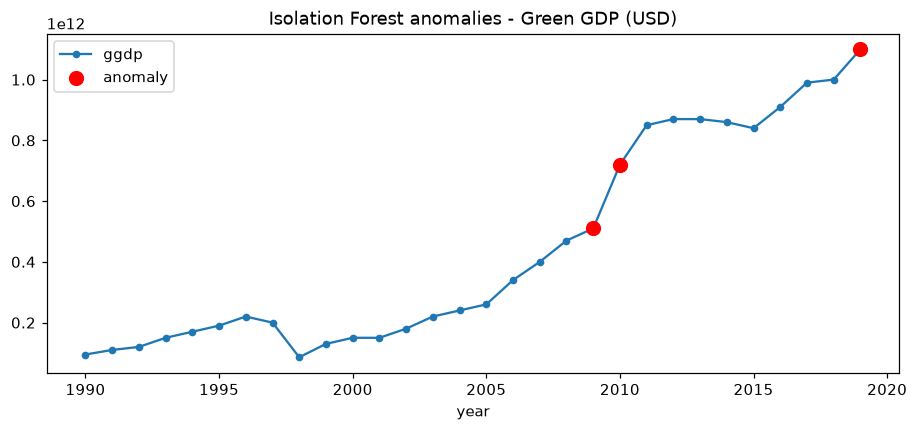

             value   score
year                      
2009  5.100000e+11 -0.0099
2010  7.200000e+11 -0.0361
2019  1.100000e+12 -0.1322


In [41]:
iforest_anomalies("ggdp")

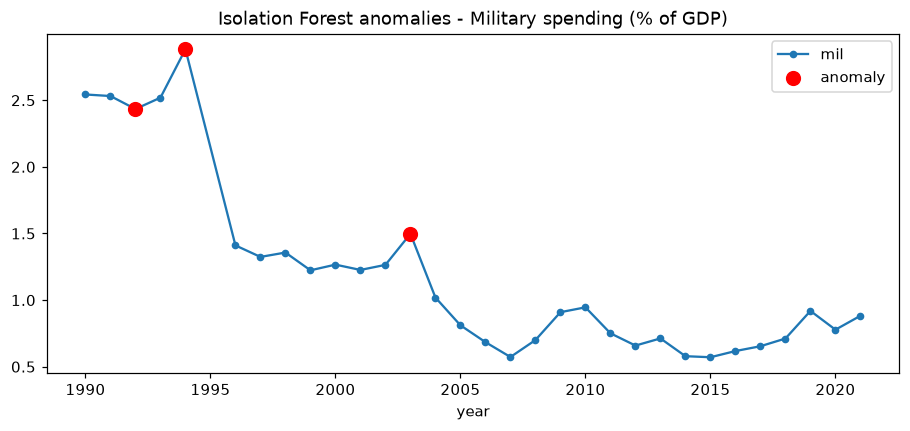

         value   score
year                  
1992  2.433922 -0.0892
1994  2.882670 -0.1973
2003  1.497742 -0.0282


In [42]:
iforest_anomalies("mil")

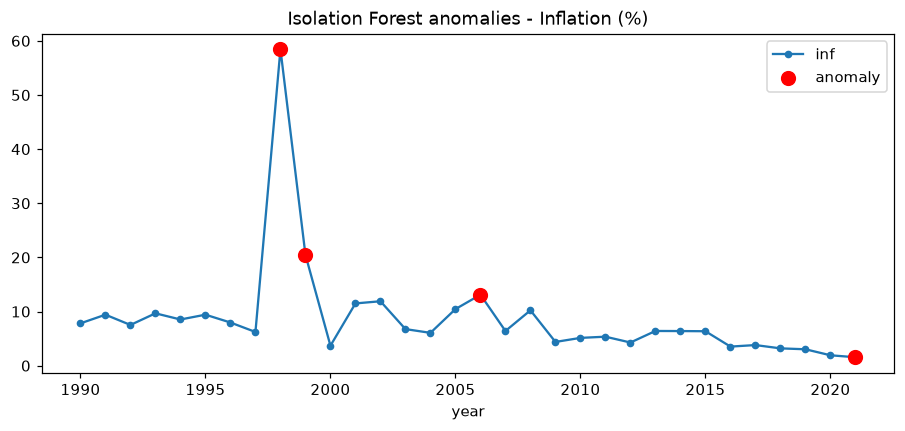

          value   score
year                   
1998  58.451044 -0.3054
1999  20.477831 -0.1635
2006  13.108672 -0.0018
2021   1.560130 -0.0207


In [43]:
iforest_anomalies("inf")

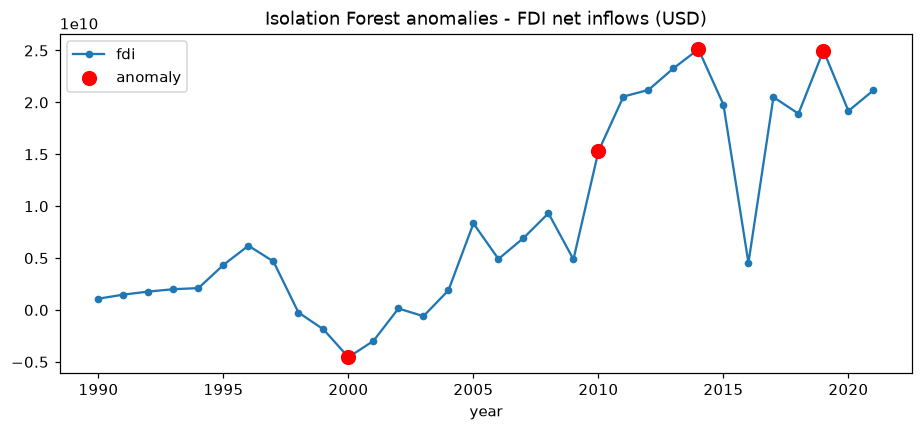

             value   score
year                      
2000 -4.550355e+09 -0.0412
2010  1.529201e+10 -0.0063
2014  2.512073e+10 -0.0086
2019  2.499355e+10 -0.0008


In [44]:
iforest_anomalies("fdi")

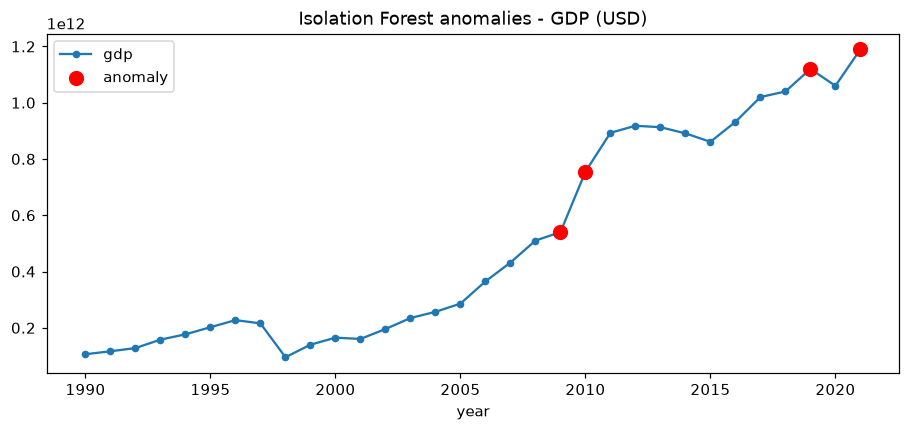

              value   score
year                       
2009   540000000000 -0.0014
2010   755000000000 -0.0221
2019  1120000000000 -0.0329
2021  1190000000000 -0.1107


In [45]:
iforest_anomalies("gdp")

## 2.2 Change point detection (ruptures PELT, RBF cost, on the standardised series)

In [46]:
def change_points(col, pen=3):
    s = get(col)
    x = ((s - s.mean()) / s.std()).values
    bkps = rpt.Pelt(model="rbf", min_size=3).fit(x).predict(pen=pen)
    years = [int(s.index[b]) for b in bkps[:-1]]   # first year of each new regime
    ax = s.plot(marker="o", ms=4, title=f"Change points (PELT) - {NAMES[col]}")
    for y in years:
        ax.axvline(y - 0.5, color="red", ls="--")
    for a, b in zip([0] + bkps[:-1], bkps):
        seg = s.iloc[a:b]
        ax.hlines(seg.mean(), seg.index[0] - 0.5, seg.index[-1] + 0.5, color="green", lw=2)
    plt.show()
    print("Change points (first year of new regime):", years)
    for a, b in zip([0] + bkps[:-1], bkps):
        seg = s.iloc[a:b]
        print(f"  segment {seg.index[0]}-{seg.index[-1]}: mean = {seg.mean():.4g}")

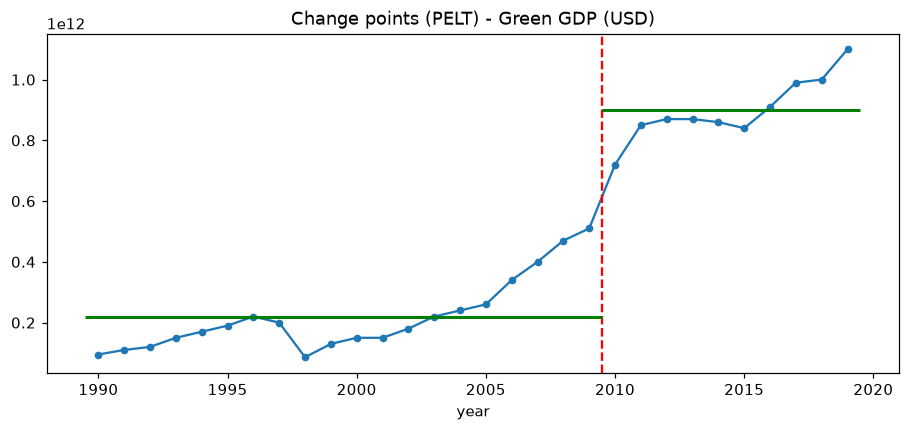

Change points (first year of new regime): [2010]
  segment 1990-2009: mean = 2.196e+11
  segment 2010-2019: mean = 9.01e+11


In [47]:
change_points("ggdp")

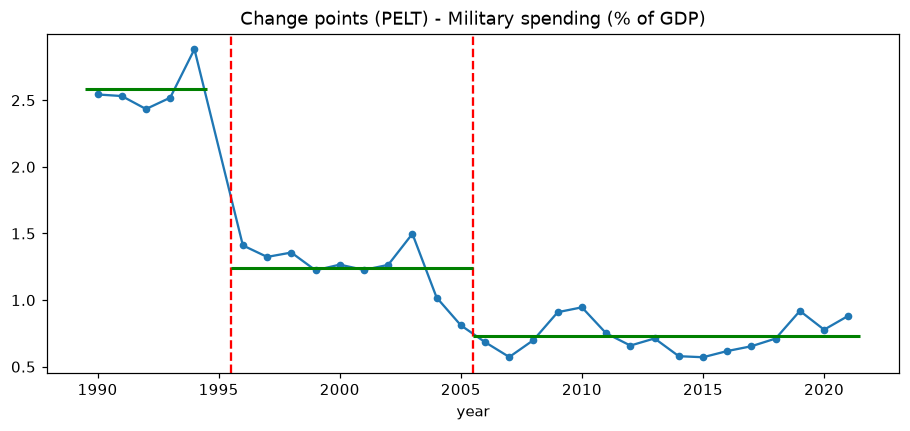

Change points (first year of new regime): [1996, 2006]
  segment 1990-1994: mean = 2.582
  segment 1996-2005: mean = 1.24
  segment 2006-2021: mean = 0.7279


In [48]:
change_points("mil")

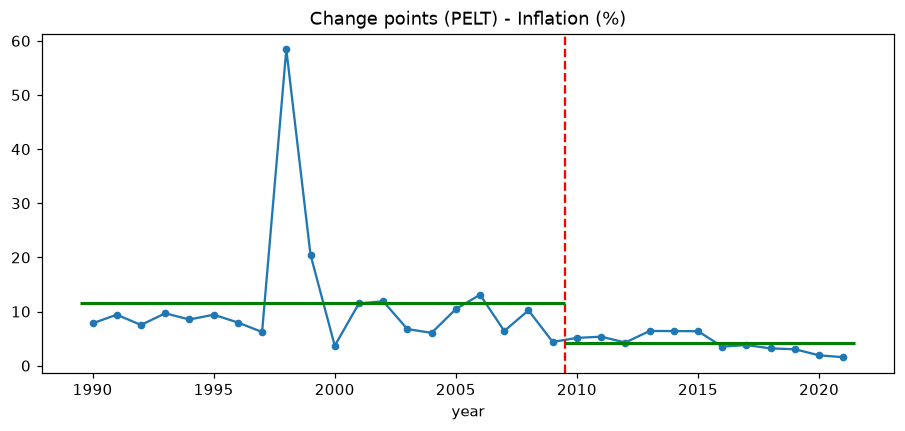

Change points (first year of new regime): [2010]
  segment 1990-2009: mean = 11.5
  segment 2010-2021: mean = 4.249


In [49]:
change_points("inf")

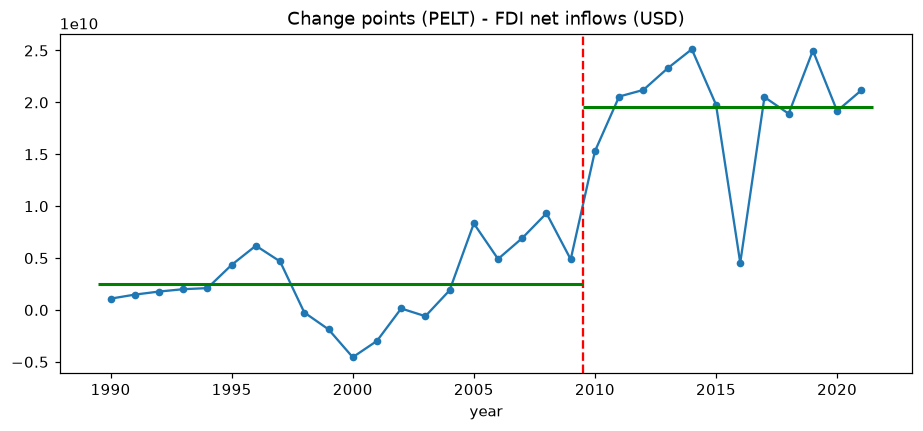

Change points (first year of new regime): [2010]
  segment 1990-2009: mean = 2.493e+09
  segment 2010-2021: mean = 1.954e+10


In [50]:
change_points("fdi")

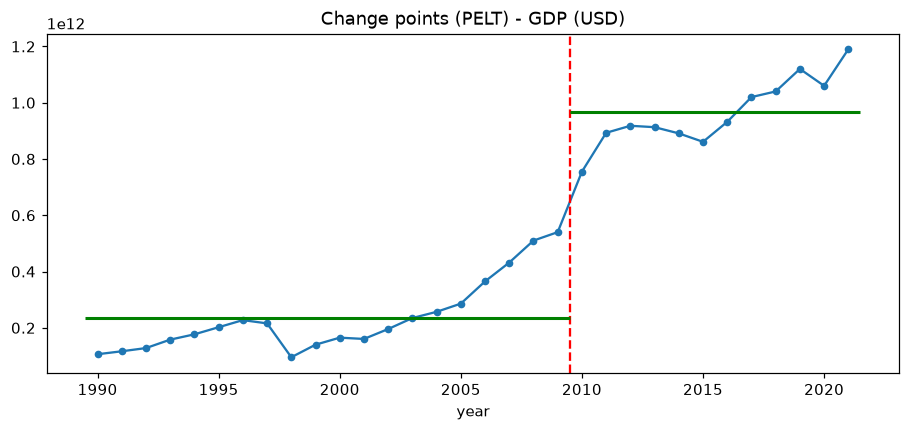

Change points (first year of new regime): [2010]
  segment 1990-2009: mean = 2.356e+11
  segment 2010-2021: mean = 9.661e+11


In [51]:
change_points("gdp")